# Simulated LST-1 data from simulst

What `uuls.simdata.simulate` returns: a DL3 folder written by simulst (separate environment, gammapy 1.3,
run as a subprocess) for a set of pointings. The example is four 20-minute wobble runs at 0.4 deg around the
centre of the S240615dg region, simulated once with background only and once with a power-law point source
at the centre. The two simulations use the same seed, so they share every background event. simulst's IRF
production "2025_2p5" is used, whose effective area, PSF and energy dispersion extend to 2.5 deg offset.

Inputs: target (RA 7.53, Dec 45.81), a stand-in merger time, NSB 0.14, seed 1, production 2025_2p5, source
dN/dE = 1e-11 (E / 1 TeV)^-2 cm-2 s-1 TeV-1. Cache entries `simulst_dl3/<key>`, printed when the
simulations are loaded.

Outputs: figures in `outputs/figures/0_tools/03_simulated_data/` and the pointings table
`outputs/results/0_tools/03_simulated_data/pointings.ecsv`, read by `04_reduce`.

In [16]:
import json

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import AltAz, EarthLocation, SkyCoord, get_body, get_sun
from astropy.io import fits
from astropy.table import Table
from astropy.time import Time
from gammapy.data import DataStore

from uuls import paths, pointings, simdata
from uuls.figures import FigureSaver

figs = FigureSaver("0_tools", "03_simulated_data")
results = paths.RESULTS / "0_tools" / "03_simulated_data"
results.mkdir(parents=True, exist_ok=True)

The target, the stand-in merger time and the simulation settings. The merger time only fixes the night; the
observation starts at the first moment it is dark and the target is high.

In [17]:
TARGET = SkyCoord(7.53, 45.81, unit="deg", frame="icrs")
T0 = Time("2025-10-20T20:30:00", scale="utc")   # stand-in merger time
N_RUNS, RUN_MIN, WOBBLE_DEG = 4, 20, 0.4
NSB, SEED, PRODUCTION = 0.14, 1, "2025_2p5"
SOURCE = simdata.PowerLawSource(ra=TARGET.ra.deg, dec=TARGET.dec.deg, amplitude=1e-11, index=2.0)
SITE = EarthLocation.of_site("Roque de los Muchachos")

Start time: on a one-minute grid from 30 minutes after the merger, the first minute from which, for the whole
80 minutes of observation, the target stays above 60 deg altitude, the Sun below -18 deg and the Moon below
the horizon.

In [18]:
grid = T0 + np.arange(30, 12 * 60) * u.min
frame = AltAz(obstime=grid, location=SITE)
alt = TARGET.transform_to(frame).alt.deg
sun = get_sun(grid).transform_to(frame).alt.deg
moon = get_body("moon", grid, SITE).transform_to(frame).alt.deg
ok = (alt > 60) & (sun < -18) & (moon < 0)
n_obs = N_RUNS * RUN_MIN
start = next(i for i in range(len(grid) - n_obs) if ok[i:i + n_obs + 1].all())
T_START = grid[start]
print(f"observation {T_START.isot} to {(T_START + n_obs * u.min).isot} UTC, "
      f"{(T_START - T0).to(u.h):.2f} after the merger")
print(f"target altitude {alt[start]:.1f} to {alt[start + n_obs]:.1f} deg, highest {alt.max():.1f} deg")

observation 2025-10-20T21:40:00.000 to 2025-10-20T23:00:00.000 UTC, 1.17 h after the merger
target altitude 60.1 to 70.7 deg, highest 72.8 deg


Altitudes of the target, Sun and Moon through the night, with the four runs shaded.

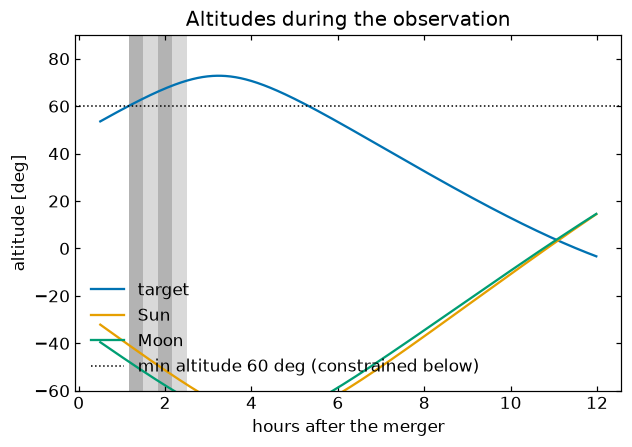

In [19]:
hours = (grid - T0).to_value(u.h)
fig, ax = plt.subplots()
for y, lab in zip([alt, sun, moon], ["target", "Sun", "Moon"]):
    ax.plot(hours, y, label=lab)
for k in range(N_RUNS):
    t1 = (T_START - T0).to_value(u.h) + k * RUN_MIN / 60
    ax.axvspan(t1, t1 + RUN_MIN / 60, color="0.85" if k % 2 else "0.7", lw=0)
ax.axhline(60, color="k", ls=":", lw=1, label="min altitude 60 deg (constrained below)")
ax.set(xlabel="hours after the merger", ylabel="altitude [deg]", ylim=(-60, 90), title="Altitudes during the observation")
ax.legend(loc="lower left")
figs.save(fig, "altitude")
plt.show()

Four wobble runs at 0.4 deg, position angles 0, 90, 180 and 270 deg, back to back (`uuls.pointings.wobble`).
The table and the simulation settings are written for the next notebook.

In [20]:
point = pointings.wobble(TARGET, T_START, N_RUNS, RUN_MIN * u.min, offset=WOBBLE_DEG, t0=T0)
pointings.write(point, results / "pointings.ecsv")
(results / "simulation.json").write_text(json.dumps(
    {"nsb": NSB, "seed": SEED, "production": PRODUCTION, "source": vars(SOURCE),
     "target": [TARGET.ra.deg, TARGET.dec.deg]}, indent=1))
point

obs_id,ra,dec,t_start,duration,wobble_angle
,deg,deg,,s,
int64,float64,float64,Time,float64,float64
1,7.530000000000001,46.209999999999994,2025-10-20T21:40:00.000,1200.0,0.0
2,8.103845320454381,45.808563713710505,2025-10-20T22:00:00.000,1200.0,90.0
3,7.530000000000001,45.41,2025-10-20T22:20:00.000,1200.0,180.0
4,6.956154679545621,45.808563713710505,2025-10-20T22:40:00.000,1200.0,270.0


The two simulations. The first call of each runs simulst (20 to 60 s per 20-minute run on this machine);
later calls load the cached folder.

In [22]:
dl3_bkg = simdata.simulate(point, nsb=NSB, seed=SEED, production=PRODUCTION)
dl3_src = simdata.simulate(point, nsb=NSB, seed=SEED, source=SOURCE, production=PRODUCTION)
print(dl3_bkg)
print(dl3_src)

RuntimeError: simulst job failed (status 1), log /home/jjimenezq/projects/uncertain-uls/cache/simulst_dl3/33cf7015fe2d/simulst.log:
Traceback (most recent call last):
  File "/home/jjimenezq/projects/uncertain-uls/scripts/simulst_job.py", line 44, in <module>
    from simulst.background.library import BackgroundLibrary
ModuleNotFoundError: No module named 'simulst'


What simulst recorded per run: event count, the drawn background norm, library flags (predicted or
extrapolated bins, dropped bands), the IRF production, the outer edge of its offset axis and the event
offset cut.

In [ ]:
summary = simdata.run_summary(dl3_src)
summary["obs_id", "n_events", "source", "BKGNORM", "BKGPRED", "BKGEXTRP", "BKGDROP", "MCPROD", "IRFORGHI", "OFFMAX",
        "LIVETIME", "seconds"]

obs_id,n_events,source,BKGNORM,BKGPRED,BKGEXTRP,BKGDROP,MCPROD,IRFORGHI,OFFMAX,LIVETIME,seconds
int64,int64,bool,float64,bool,bool,str1,str8,float64,float64,float64,float64
1,1139172,True,1.0364667931688805,False,False,,2025_2p5,2.5,2.5,1141.631999999996,26.4
2,1170343,True,0.9899188640973631,False,False,,2025_2p5,2.5,2.5,1139.7767999999958,26.3
3,746531,True,0.6997689075630251,False,False,,2025_2p5,2.5,2.5,1138.1879999999958,20.7
4,1063565,True,1.236218487394958,False,False,,2025_2p5,2.5,2.5,1138.1879999999958,25.3


The folder is a standard DL3 data store: one events file per run with GTI, pointing and full-enclosure IRFs,
and the background model of each run registered as its `bkg` HDU.

In [ ]:
store = DataStore.from_dir(dl3_src)
display(store.obs_table["OBS_ID", "RA_PNT", "DEC_PNT", "ZEN_PNT", "ALT_PNT", "AZ_PNT", "ONTIME", "LIVETIME"])
print(sorted(set(store.hdu_table["HDU_TYPE"])))

OBS_ID,RA_PNT,DEC_PNT,ZEN_PNT,ALT_PNT,AZ_PNT,ONTIME,LIVETIME
,deg,deg,deg,deg,deg,s,s
int64,float64,float64,float64,float64,float64,float64,float64
1,7.530000000000001,46.209999999999994,28.47360075697327,61.52639924302673,43.99222433238763,1199.9999999999957,1141.631999999996
2,8.103845320454381,45.808563713710505,25.628819842782633,64.37118015721737,41.278007395904226,1199.9999999999957,1139.7767999999958
3,7.530000000000001,45.41,22.31061442329454,67.68938557670546,36.130771032677856,1200.0000000000052,1138.1879999999958
4,6.956154679545621,45.808563713710505,20.02163261225712,69.97836738774288,27.301082075609756,1200.0000000000052,1138.1879999999958


['aeff', 'bkg', 'edisp', 'events', 'gti', 'pointing', 'psf']


Events of each run in both simulations. With the same seed and obs_id, the background-only event list is
contained in the one with source (same time and energy for every background event), so the difference is the
source.

In [ ]:
def events(dl3, obs_id):
    return Table(fits.getdata(dl3 / f"dl3_LST-1.Run{obs_id:05d}.fits", "EVENTS"))


def key(ev):
    return np.round(ev["TIME"], 6) + 1j * ev["ENERGY"]


rows = []
for obs_id in point["obs_id"]:
    eb, es = events(dl3_bkg, obs_id), events(dl3_src, obs_id)
    hb, hs = eb["ENERGY"] > 0.6, es["ENERGY"] > 0.6
    rows.append({"obs_id": obs_id, "background": len(eb), "with source": len(es), "source": len(es) - len(eb),
                 "fraction shared": np.isin(key(eb), key(es)).mean(),
                 "background > 0.6 TeV": hb.sum(), "source > 0.6 TeV": hs.sum() - hb.sum()})
Table(rows=rows)

obs_id,background,with source,source,fraction shared,background > 0.6 TeV,source > 0.6 TeV
int64,int64,int64,int64,float64,int64,int64
1,1138733,1139172,439,1.0,2077,46
2,1169930,1170343,413,1.0,1843,51
3,746118,746531,413,1.0,1080,53
4,1063166,1063565,399,1.0,1711,43


Reconstructed energy of all events of the four runs. The background extends down to 10 GeV and holds almost
all events; a few thousand remain above the analysis threshold of 0.6 TeV. The source spectrum is the
difference of the two event lists.

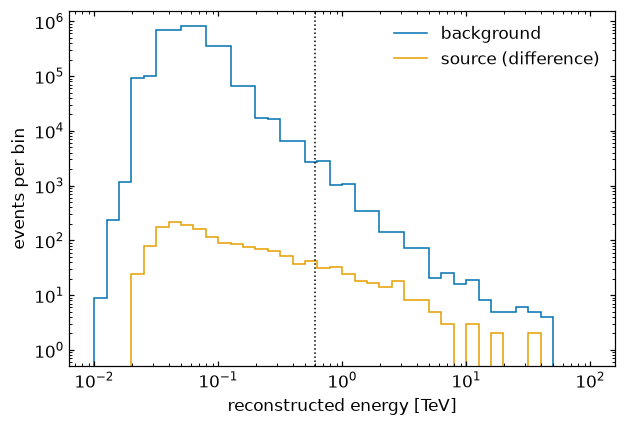

In [ ]:
eb = np.concatenate([events(dl3_bkg, i)["ENERGY"] for i in point["obs_id"]])
es = np.concatenate([events(dl3_src, i)["ENERGY"] for i in point["obs_id"]])
bins = np.geomspace(0.01, 100, 41)
nb, _ = np.histogram(eb, bins)
ns, _ = np.histogram(es, bins)
fig, ax = plt.subplots()
ax.stairs(nb, bins, label="background")
ax.stairs(ns - nb, bins, label="source (difference)")
ax.axvline(0.6, color="k", ls=":", lw=1)
ax.set(xscale="log", yscale="log", xlabel="reconstructed energy [TeV]", ylabel="events per bin", ylim=(0.5, None))
ax.legend()
figs.save(fig, "energy")
plt.show()

Event offsets from each run's pointing above 0.6 TeV, per unit solid angle (dN / d offset^2). simulst cuts
events beyond 2.5 deg (`OFFMAX`), which is also where the IRFs of production 2025_2p5 end. The older production
2025 ends at 1.1 deg: with it, the background events between 1.1 and 2.5 deg had no exposure.

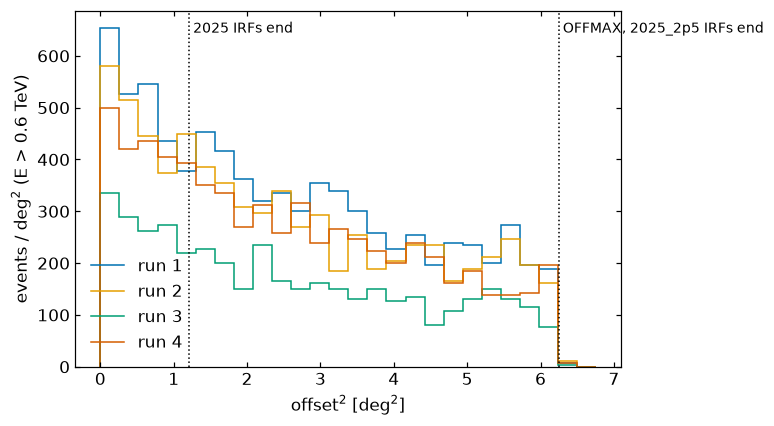

In [ ]:
fig, ax = plt.subplots()
edges = np.linspace(0, 2.6 ** 2, 27)   # equal solid angle per bin
for obs_id, pnt in zip(point["obs_id"], pointings.coords(point)):
    ev = events(dl3_bkg, obs_id)
    ev = ev[ev["ENERGY"] > 0.6]
    off = SkyCoord(ev["RA"], ev["DEC"], unit="deg").separation(pnt).deg
    n, _ = np.histogram(off ** 2, edges)
    ax.stairs(n / np.diff(edges), edges, label=f"run {obs_id}")
for x, lab in [(1.1, "2025 IRFs end"), (2.5, "OFFMAX, 2025_2p5 IRFs end")]:
    ax.axvline(x ** 2, color="k", ls=":", lw=1)
    ax.text(x ** 2, ax.get_ylim()[1] * 0.97, f" {lab}", va="top", fontsize=9)
ax.set(xlabel="offset$^2$ [deg$^2$]", ylabel="events / deg$^2$ (E > 0.6 TeV)")
ax.legend(loc="lower left")
figs.save(fig, "offsets")
plt.show()

Sky positions of the events above 0.6 TeV, all four runs, background only and with source. The crosses are
the pointings, the circle the source position.

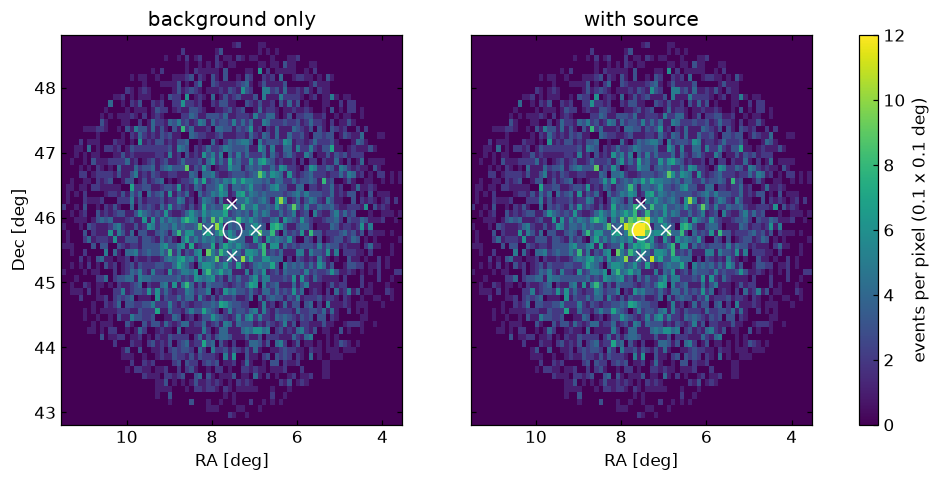

In [ ]:
def all_events(dl3):
    ev = Table(np.concatenate([events(dl3, i).as_array() for i in point["obs_id"]]))
    return ev[ev["ENERGY"] > 0.6]


fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
ra_bins = np.linspace(TARGET.ra.deg - 4, TARGET.ra.deg + 4, 81)
dec_bins = np.linspace(TARGET.dec.deg - 3, TARGET.dec.deg + 3, 61)
for ax, dl3, title in zip(axes, [dl3_bkg, dl3_src], ["background only", "with source"]):
    ev = all_events(dl3)
    h = ax.hist2d(ev["RA"], ev["DEC"], bins=[ra_bins, dec_bins], cmap="viridis", vmax=12)
    pnt = pointings.coords(point)
    ax.plot(pnt.ra.deg, pnt.dec.deg, "wx")
    ax.plot(TARGET.ra.deg, TARGET.dec.deg, "o", mfc="none", mec="w", ms=12)
    ax.set(title=title, xlabel="RA [deg]")
    ax.invert_xaxis()
axes[0].set_ylabel("Dec [deg]")
fig.colorbar(h[3], ax=axes, label="events per pixel (0.1 x 0.1 deg)")
figs.save(fig, "event_maps")
plt.show()

Squared angular distance of the events above 0.6 TeV from the source position. The excess sits within a few
hundredths of a square degree, the extent of the PSF at these energies.

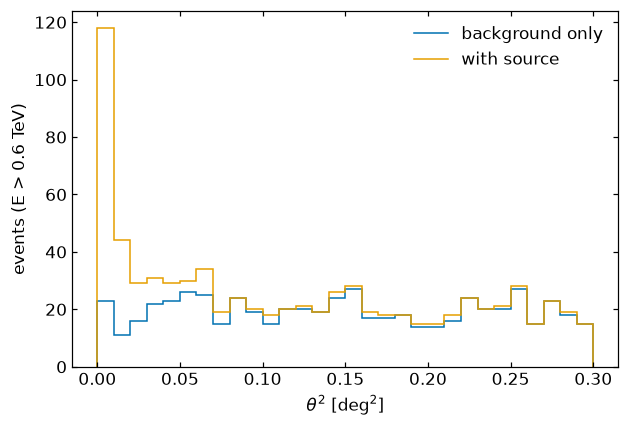

In [ ]:
fig, ax = plt.subplots()
edges = np.linspace(0, 0.3, 31)
for dl3, label in [(dl3_bkg, "background only"), (dl3_src, "with source")]:
    ev = all_events(dl3)
    th2 = SkyCoord(ev["RA"], ev["DEC"], unit="deg").separation(TARGET).deg ** 2
    ax.stairs(np.histogram(th2, edges)[0], edges, label=label)
ax.set(xlabel=r"$\theta^2$ [deg$^2$]", ylabel="events (E > 0.6 TeV)")
ax.legend()
figs.save(fig, "theta2")
plt.show()

Effective area of the first run against true energy at several offsets. Below 0.1 deg the area is a copy of
the innermost offset bin (padding), as is the band 2.5-2.6 deg of the outermost one; beyond 2.6 deg it is zero.

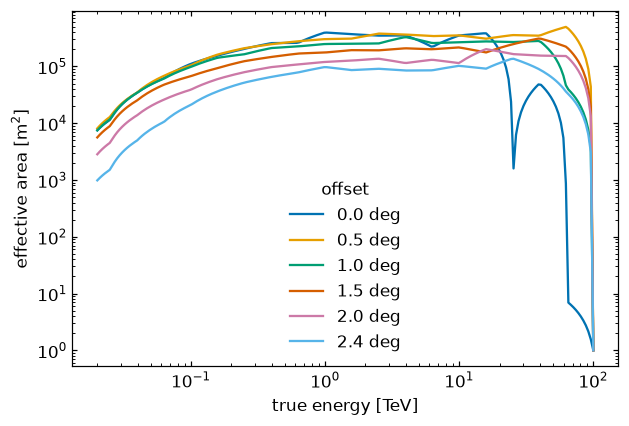

In [ ]:
obs = store.obs(int(point["obs_id"][0]))
e_true = np.geomspace(0.02, 100, 200) * u.TeV
fig, ax = plt.subplots()
for off in [0.0, 0.5, 1.0, 1.5, 2.0, 2.4]:
    area = obs.aeff.evaluate(offset=off * u.deg, energy_true=e_true).to_value(u.m ** 2)
    ax.plot(e_true, np.where(area > 0, area, np.nan), label=f"{off} deg")
ax.set(xscale="log", yscale="log", xlabel="true energy [TeV]", ylabel="effective area [m$^2$]")
ax.legend(title="offset")
figs.save(fig, "aeff")
plt.show()

Radial exposure profile of the same run, effective area times livetime against offset from the pointing,
at three true energies. This is what the reduction turns into exposure maps; the analysis cuts at 2.5 deg.

0.1 TeV: relative to the centre at 1.0 / 1.5 / 2.0 / 2.5 deg: 0.88 0.61 0.35 0.19
1.0 TeV: relative to the centre at 1.0 / 1.5 / 2.0 / 2.5 deg: 0.63 0.44 0.30 0.25
10.0 TeV: relative to the centre at 1.0 / 1.5 / 2.0 / 2.5 deg: 0.76 0.62 0.33 0.29


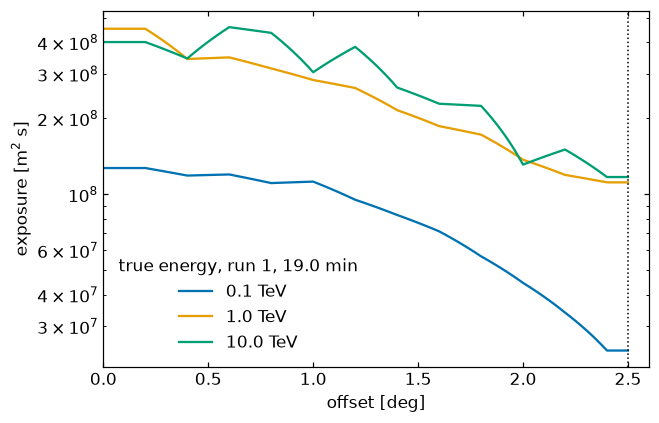

In [ ]:
offsets = np.linspace(0, 2.5, 101) * u.deg
livetime = obs.observation_live_time_duration
fig, ax = plt.subplots()
for e in [0.1, 1.0, 10.0] * u.TeV:
    expo = (obs.aeff.evaluate(offset=offsets, energy_true=e) * livetime).to_value(u.m ** 2 * u.s)
    ax.plot(offsets, expo, label=f"{e:.1f}")
    print(f"{e:.1f}: relative to the centre at 1.0 / 1.5 / 2.0 / 2.5 deg: "
          + " ".join(f"{np.interp(x, offsets.value, expo) / expo[0]:.2f}" for x in (1.0, 1.5, 2.0, 2.5)))
ax.axvline(2.5, color="k", ls=":", lw=1)
ax.set(xlabel="offset [deg]", ylabel="exposure [m$^2$ s]", yscale="log", xlim=(0, 2.6))
ax.legend(title=f"true energy, run {point['obs_id'][0]}, {livetime.to(u.min):.1f}")
figs.save(fig, "exposure_profile")
plt.show()

Outputs: `outputs/results/0_tools/03_simulated_data/pointings.ecsv` and `simulation.json` (NSB, seed,
source), the two cached DL3 folders printed above, and the figures `altitude`, `energy`, `offsets`,
`event_maps`, `theta2`, `aeff`, `exposure_profile` in `outputs/figures/0_tools/03_simulated_data/`.